# ENEM 2020: visões sobre as notas

Este notebook lê o modelo dimensional carregado no MySQL e gera as visões pedidas no teste. Cada gráfico é salvo em `docs/img/` e aparece no README.

- **Nota como indicador**: a média das quatro provas objetivas por participante (ADR-0006), só para quem esteve presente nas quatro.
- **Médias e medianas por grupo** usam todos os participantes presentes nas quatro provas. Nos gráficos de barras, a barra é a média e a marca vertical é a mediana; nas linhas, a linha cheia é a média e a linha fina com marcador vazado é a mediana. Quando a média fica acima da mediana, há um grupo menor de notas altas puxando a média para cima.
- **Distribuições e correlações** usam uma amostra determinística de cerca de 10% dos participantes presentes nas quatro provas (`CRC32(nu_inscricao) % 10 = 0`). A amostra é a mesma a cada execução.

Para executar: `docker compose run --rm app jupyter nbconvert --to notebook --execute --inplace notebooks/analise_enem_2020.ipynb`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymysql
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.etl.load import conectar  # noqa: E402

PASTA_IMG = RAIZ / "docs" / "img"
PASTA_IMG.mkdir(parents=True, exist_ok=True)

# Paleta e tinta validadas para leitura com daltonismo (fundo claro)
SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
TINTA_SUAVE = "#898781"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # azul, laranja, aqua, amarelo
AZUL = SERIES[0]
DIVERGENTE = LinearSegmentedColormap.from_list(
    "divergente", ["#e34948", "#f0efec", "#2a78d6"]
)  # vermelho (negativo), cinza neutro, azul (positivo)

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 110, "savefig.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TINTA, "axes.labelcolor": TINTA_SECUNDARIA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 24,  # espaço para o subtítulo entre o título e o gráfico
    "axes.titlecolor": TINTA, "axes.edgecolor": EIXO,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelcolor": TINTA_SECUNDARIA, "ytick.labelcolor": TINTA_SECUNDARIA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})


def consultar(sql: str) -> pd.DataFrame:
    """Executa uma consulta no MySQL e devolve um DataFrame."""
    conexao = conectar()
    try:
        with conexao.cursor() as cursor:
            cursor.execute(sql)
            colunas = [c[0] for c in cursor.description]
            df = pd.DataFrame(cursor.fetchall(), columns=colunas)
    finally:
        conexao.close()
    # Decimal do MySQL vira float para os cálculos
    for coluna in df.columns:
        if df[coluna].dtype == object and len(df) and type(df[coluna].iloc[0]).__name__ == "Decimal":
            df[coluna] = df[coluna].astype(float)
    return df


def consultar_grande(sql: str, lote: int = 500_000) -> pd.DataFrame:
    """Lê uma consulta grande em lotes, sem trazer tudo para a memória de uma vez."""
    conexao = conectar()
    partes = []
    try:
        with conexao.cursor(pymysql.cursors.SSCursor) as cursor:
            cursor.execute(sql)
            colunas = [c[0] for c in cursor.description]
            while linhas := cursor.fetchmany(lote):
                partes.append(pd.DataFrame(linhas, columns=colunas))
    finally:
        conexao.close()
    return pd.concat(partes, ignore_index=True)


def agregar(df: pd.DataFrame, grupo, valor: str = "media") -> pd.DataFrame:
    """Número de participantes, média e mediana de `valor` por grupo."""
    return df.groupby(grupo, observed=True)[valor].agg(
        participantes="size", media="mean", mediana="median"
    ).reset_index()


LEGENDA_BARRAS = [Patch(color="#2a78d6", label="Média"),
                  Line2D([], [], color="#0b0b0b", marker="|", linestyle="", markersize=12,
                         markeredgewidth=2, label="Mediana")]


def rotulo_par(media: float, mediana: float, separador: str = " | ") -> str:
    """Texto padrão com os dois valores, sempre juntos e na mesma ordem."""
    return f"média {num(media)}{separador}mediana {num(mediana)}"


def barras_com_mediana(ax, rotulos, medias, medianas, folga: float = 2.0, fonte: float = 8.5) -> None:
    """Desenha a média em barras horizontais e a mediana como uma marca sobre cada barra.

    Toda barra recebe o rótulo com os dois valores, à direita do que for maior.
    """
    ax.barh(rotulos, medias, color=AZUL, height=0.6)
    ax.scatter(medianas, range(len(rotulos)), marker="|", s=260, linewidths=2.2, color=TINTA, zorder=3)
    for i, (media, mediana) in enumerate(zip(medias, medianas)):
        # Fundo da cor da superfície para a linha de referência não cortar o texto
        ax.text(max(media, mediana) + folga, i, rotulo_par(media, mediana), va="center",
                fontsize=fonte, color=TINTA, zorder=4,
                bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1})


def linha_com_mediana(ax, x, medias, medianas, cor: str, nome: str = "",
                      rotulo_inicio: str = "above", rotulo_fim: str = "above") -> None:
    """Desenha a média em linha cheia e a mediana em linha fina com marcador vazado.

    As duas pontas da série recebem o rótulo com os dois valores. `rotulo_inicio`
    e `rotulo_fim` dizem se cada rótulo fica acima ("above") ou abaixo ("below")
    dos pontos, para não cobrir outra série.
    """
    prefixo = f"{nome}: " if nome else ""
    x, medias, medianas = list(x), list(medias), list(medianas)
    ax.plot(x, medias, color=cor, marker="o", markersize=5, label=f"{prefixo}média")
    ax.plot(x, medianas, color=cor, linewidth=1.2, marker="o", markersize=5,
            markerfacecolor=SUPERFICIE, label=f"{prefixo}mediana")
    for indice, lado, alinhamento in [(0, rotulo_inicio, "left"), (-1, rotulo_fim, "right")]:
        acima = lado == "above"
        y = max(medias[indice], medianas[indice]) if acima else min(medias[indice], medianas[indice])
        ax.annotate(rotulo_par(medias[indice], medianas[indice], separador="\n"), (x[indice], y),
                    xytext=(0, 8 if acima else -8), textcoords="offset points",
                    ha=alinhamento, va="bottom" if acima else "top", fontsize=8.5, color=TINTA)


def num(valor: float, casas: int = 1) -> str:
    """Formata número no padrão brasileiro (vírgula decimal, ponto de milhar)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def salvar(fig, nome: str) -> None:
    """Salva o gráfico em docs/img com margens ajustadas."""
    fig.tight_layout()
    fig.savefig(PASTA_IMG / f"{nome}.png", bbox_inches="tight", pad_inches=0.25)
    plt.show()


def subtitulo(ax, texto: str) -> None:
    """Escreve uma linha de contexto abaixo do título do gráfico."""
    ax.text(0, 1.015, texto, transform=ax.transAxes, color=TINTA_SECUNDARIA, fontsize=9, va="bottom")


PROVAS = {"nu_nota_cn": "Ciências da Natureza", "nu_nota_ch": "Ciências Humanas",
          "nu_nota_lc": "Linguagens e Códigos", "nu_nota_mt": "Matemática"}

In [2]:
amostra = consultar("""
    SELECT f.nu_nota_cn, f.nu_nota_ch, f.nu_nota_lc, f.nu_nota_mt, f.nu_nota_redacao,
           f.nu_nota_comp1, f.nu_nota_comp2, f.nu_nota_comp3, f.nu_nota_comp4, f.nu_nota_comp5,
           f.nu_media_objetivas AS media, f.tp_status_redacao,
           p.tp_faixa_etaria, p.ds_sexo, p.ds_cor_raca, p.ds_escola, p.ds_treineiro,
           e.ds_dependencia_adm_esc, e.ds_localizacao_esc, l.sg_uf_prova,
           q.q001, q.q002, q.q005, q.q006, q.q008, q.q010, q.q024, q.q025
    FROM fato_participacao f
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    JOIN dim_escola e ON e.sk_escola = f.sk_escola
    JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL
      AND CRC32(f.nu_inscricao) % 10 = 0
""")
print(f"Amostra: {len(amostra):,} participantes presentes nas quatro provas")

Amostra: 258,587 participantes presentes nas quatro provas


In [3]:
# Base completa dos presentes nas quatro provas, com os atributos usados nos
# agrupamentos. Média e mediana por grupo saem desta mesma base.
base = consultar_grande("""
    SELECT CAST(f.nu_media_objetivas AS DOUBLE) AS media, f.tp_status_redacao,
           p.tp_faixa_etaria, p.ds_faixa_etaria, p.ds_sexo, p.ds_cor_raca, p.ds_escola,
           e.ds_dependencia_adm_esc, l.sg_uf_prova, q.q002, q.q006, q.q024, q.q025
    FROM fato_participacao f
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    JOIN dim_escola e ON e.sk_escola = f.sk_escola
    JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL
""")
for coluna in base.columns.drop("media"):
    base[coluna] = base[coluna].astype("category")
geral = base["media"].mean()
print(f"Base completa: {len(base):,} participantes. Média {geral:.2f}, mediana {base['media'].median():.2f}")

Base completa: 2,588,681 participantes. Média 512.89, mediana 503.93


## 1. A nota como indicador de desempenho

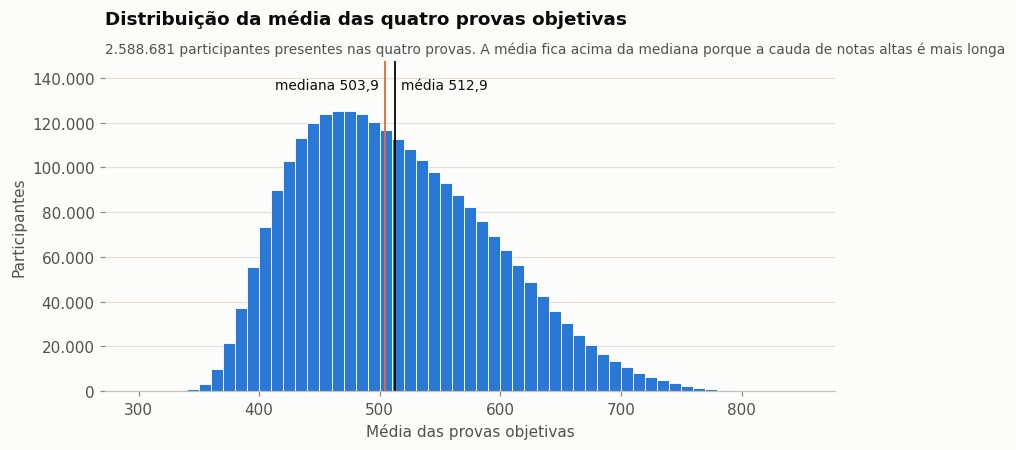

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(base["media"], bins=np.arange(300, 860, 10), color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6)
media_geral = base["media"].mean()
mediana = base["media"].median()
topo = ax.get_ylim()[1] * 1.12  # espaço acima das barras para os rótulos
ax.set_ylim(0, topo)
ax.axvline(media_geral, color=TINTA, linewidth=1.2)
ax.text(media_geral + 5, topo * 0.95, f"média {num(media_geral)}", color=TINTA, fontsize=9, va="top")
ax.axvline(mediana, color=SERIES[1], linewidth=1.2)
ax.text(mediana - 5, topo * 0.95, f"mediana {num(mediana)}", color=TINTA, fontsize=9, ha="right", va="top")
ax.set_title("Distribuição da média das quatro provas objetivas")
subtitulo(ax, f"{num(len(base), 0)} participantes presentes nas quatro provas. "
              "A média fica acima da mediana porque a cauda de notas altas é mais longa")
ax.set_xlabel("Média das provas objetivas")
ax.set_ylabel("Participantes")
ax.yaxis.set_major_formatter(lambda v, _: num(v, 0))
salvar(fig, "01_distribuicao_media")

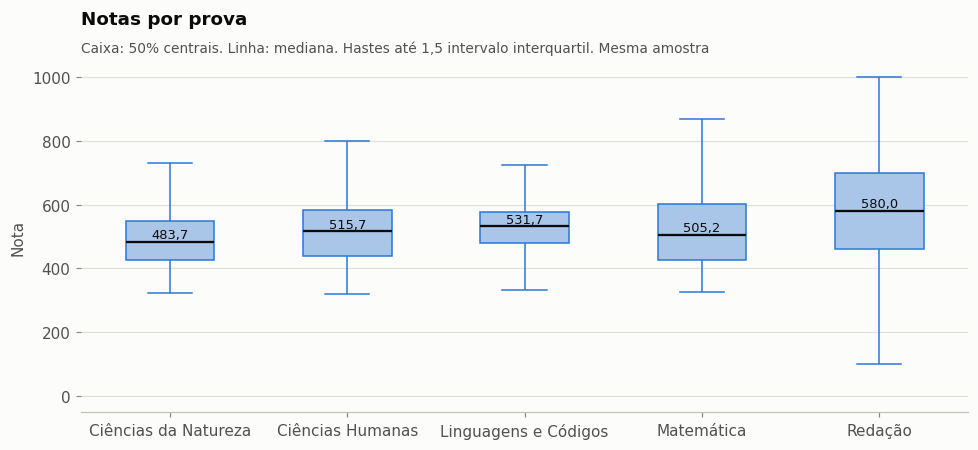

In [5]:
longo = amostra.melt(value_vars=list(PROVAS) + ["nu_nota_redacao"], var_name="prova", value_name="nota")
longo["prova"] = longo["prova"].map({**PROVAS, "nu_nota_redacao": "Redação"})
ordem = ["Ciências da Natureza", "Ciências Humanas", "Linguagens e Códigos", "Matemática", "Redação"]
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=longo, x="prova", y="nota", order=ordem, color="#9ec5f4", width=0.5, fliersize=0,
            linewidth=1, medianprops={"color": TINTA, "linewidth": 1.5},
            boxprops={"edgecolor": AZUL}, whiskerprops={"color": AZUL}, capprops={"color": AZUL}, ax=ax)
for i, prova in enumerate(ordem):
    ax.text(i, longo.loc[longo["prova"] == prova, "nota"].median() + 12,
            num(longo.loc[longo["prova"] == prova, "nota"].median()), ha="center", fontsize=8.5, color=TINTA)
ax.set_title("Notas por prova")
subtitulo(ax, "Caixa: 50% centrais. Linha: mediana. Hastes até 1,5 intervalo interquartil. Mesma amostra")
ax.set_xlabel("")
ax.set_ylabel("Nota")
salvar(fig, "02_notas_por_prova")

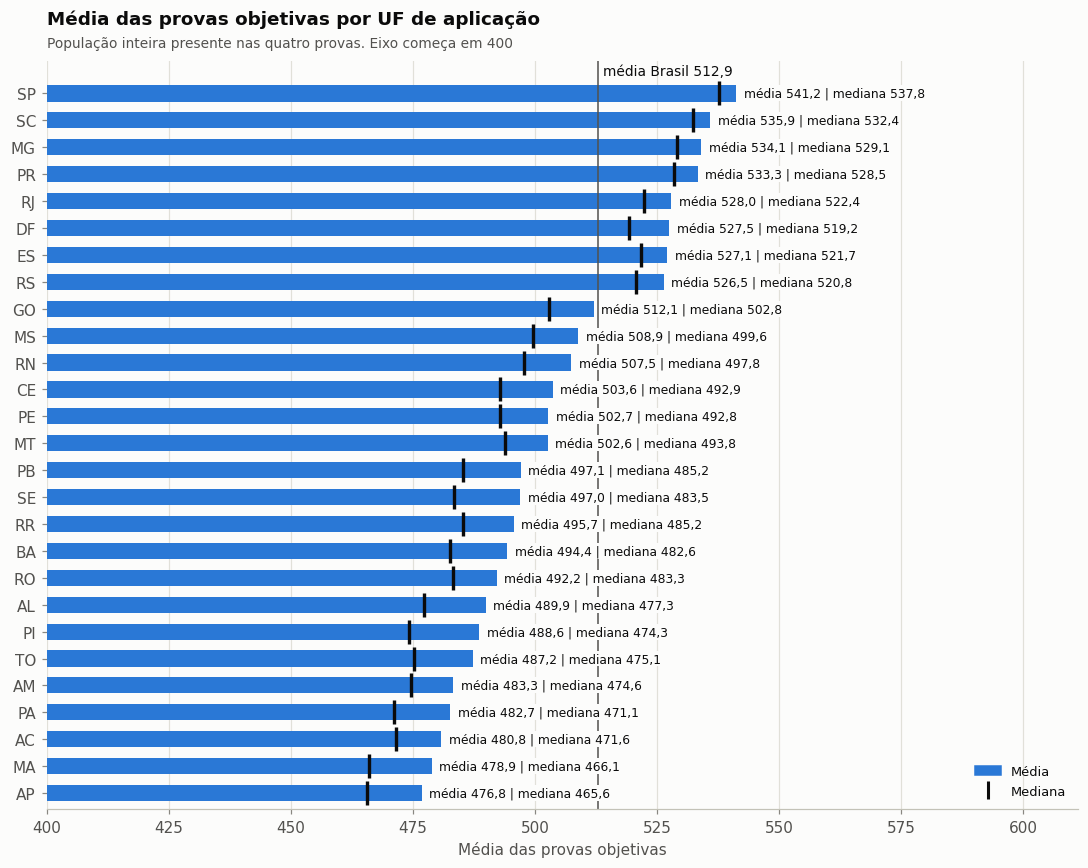

In [6]:
por_uf = agregar(base, "sg_uf_prova").sort_values("media")
fig, ax = plt.subplots(figsize=(10, 8))
barras_com_mediana(ax, por_uf["sg_uf_prova"].astype(str), por_uf["media"], por_uf["mediana"],
                   folga=1.5, fonte=8)
ax.axvline(geral, color=TINTA_SECUNDARIA, linewidth=1)
ax.text(geral + 1, len(por_uf) - 0.3, f"média Brasil {num(geral)}", fontsize=9, color=TINTA)
ax.set_xlim(400, por_uf["media"].max() + 70)
ax.set_ylim(-0.6, len(por_uf) + 0.2)
ax.legend(handles=LEGENDA_BARRAS, loc="lower right", fontsize=8.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Média das provas objetivas por UF de aplicação")
subtitulo(ax, "População inteira presente nas quatro provas. Eixo começa em 400")
ax.set_xlabel("Média das provas objetivas")
salvar(fig, "03_media_por_uf")

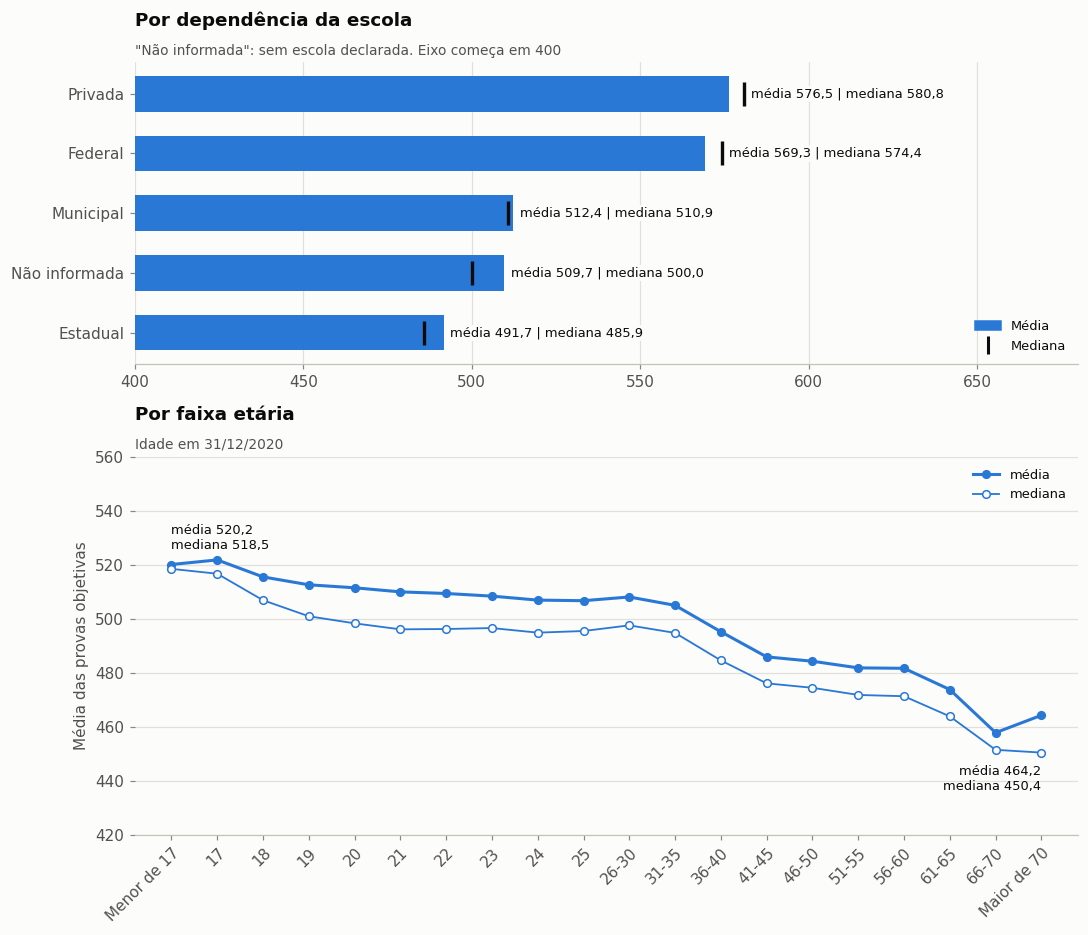

In [7]:
por_dependencia = agregar(base, "ds_dependencia_adm_esc").sort_values("media", ascending=False) \
    .reset_index(drop=True)
por_faixa = agregar(base[base["tp_faixa_etaria"].astype(int) > 0], ["tp_faixa_etaria", "ds_faixa_etaria"]) \
    .sort_values("tp_faixa_etaria")
por_dependencia = por_dependencia.sort_values("media").reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8.6), gridspec_kw={"height_ratios": [1, 1.25]})
barras_com_mediana(ax1, por_dependencia["ds_dependencia_adm_esc"].astype(str), por_dependencia["media"],
                   por_dependencia["mediana"])
ax1.set_title("Por dependência da escola")
subtitulo(ax1, "\"Não informada\": sem escola declarada. Eixo começa em 400")
ax1.set_xlim(400, 680)
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.legend(handles=LEGENDA_BARRAS, loc="lower right", fontsize=8.5)
rotulos = por_faixa["ds_faixa_etaria"].astype(str).str.replace("Entre ", "") \
    .str.replace(" anos", "").str.replace(" e ", "-")
posicoes = range(len(rotulos))
linha_com_mediana(ax2, posicoes, por_faixa["media"], por_faixa["mediana"], AZUL,
                  rotulo_inicio="above", rotulo_fim="below")
ax2.set_xticks(posicoes, rotulos)
ax2.set_xlim(-0.8, len(rotulos) - 0.2)
ax2.legend(loc="upper right", fontsize=8.5)
ax2.set_title("Por faixa etária")
subtitulo(ax2, "Idade em 31/12/2020")
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax2.set_ylim(420, 560)
ax2.set_ylabel("Média das provas objetivas")
salvar(fig, "04_media_dependencia_faixa")

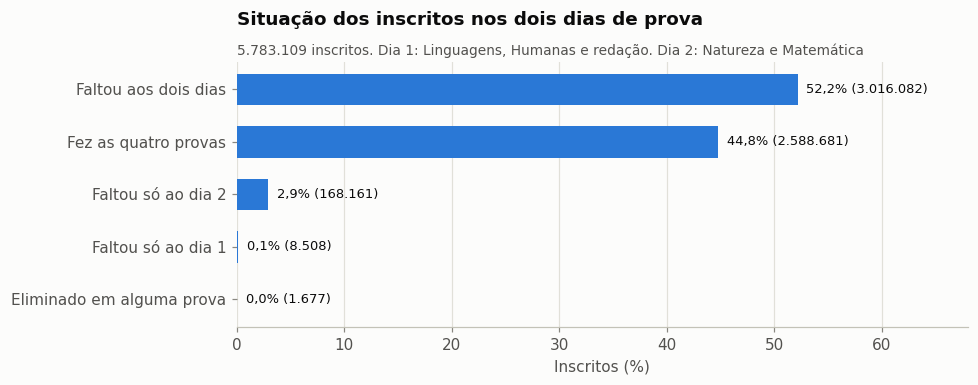

In [8]:
situacao = consultar("""
    SELECT CASE
             WHEN tp_presenca_cn = 1 AND tp_presenca_ch = 1
                  AND tp_presenca_lc = 1 AND tp_presenca_mt = 1 THEN 'Fez as quatro provas'
             WHEN (tp_presenca_lc = 0 OR tp_presenca_ch = 0)
                  AND (tp_presenca_cn = 0 OR tp_presenca_mt = 0) THEN 'Faltou aos dois dias'
             WHEN tp_presenca_lc = 0 OR tp_presenca_ch = 0 THEN 'Faltou só ao dia 1'
             WHEN tp_presenca_cn = 0 OR tp_presenca_mt = 0 THEN 'Faltou só ao dia 2'
             ELSE 'Eliminado em alguma prova'
           END AS situacao,
           COUNT(*) AS inscritos
    FROM fato_participacao
    GROUP BY situacao
""")
situacao["pct"] = 100 * situacao["inscritos"] / situacao["inscritos"].sum()
situacao = situacao.sort_values("inscritos")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(situacao["situacao"], situacao["pct"], color=AZUL, height=0.6)
for i, (pct, n) in enumerate(zip(situacao["pct"], situacao["inscritos"])):
    ax.text(pct + 0.8, i, f"{num(pct)}% ({num(n, 0)})", va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(0, 68)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Situação dos inscritos nos dois dias de prova")
subtitulo(ax, f"{num(situacao['inscritos'].sum(), 0)} inscritos. Dia 1: Linguagens, Humanas e redação. Dia 2: Natureza e Matemática")
ax.set_xlabel("Inscritos (%)")
salvar(fig, "13_situacao_inscritos")

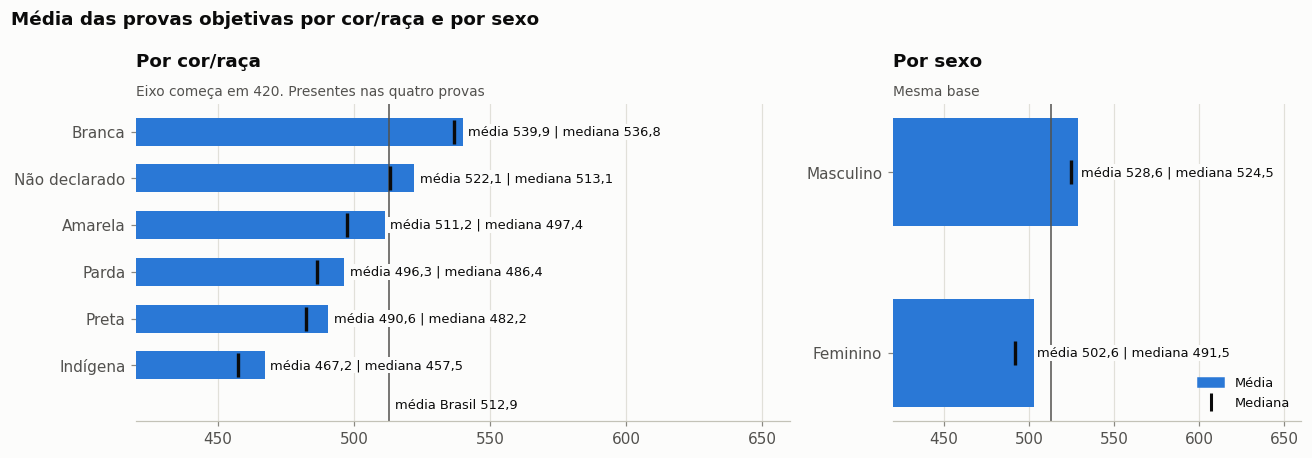

In [9]:
cor_raca = agregar(base, "ds_cor_raca").sort_values("media")
sexo = agregar(base, "ds_sexo").sort_values("media")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for ax, dados, coluna, titulo in [(ax1, cor_raca, "ds_cor_raca", "Por cor/raça"),
                                  (ax2, sexo, "ds_sexo", "Por sexo")]:
    barras_com_mediana(ax, dados[coluna].astype(str), dados["media"], dados["mediana"])
    ax.axvline(geral, color=TINTA_SECUNDARIA, linewidth=1)
    ax.set_xlim(420, 660)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
# Faixa livre abaixo da última barra para o rótulo da linha nacional
ax1.set_ylim(-1.2, len(cor_raca) - 0.4)
ax1.text(geral + 2, -0.85, f"média Brasil {num(geral)}", fontsize=8.5, color=TINTA, va="center")
ax2.legend(handles=LEGENDA_BARRAS, loc="lower right", fontsize=8.5)
subtitulo(ax1, "Eixo começa em 420. Presentes nas quatro provas")
subtitulo(ax2, "Mesma base")
fig.suptitle("Média das provas objetivas por cor/raça e por sexo", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
salvar(fig, "14_media_cor_raca_sexo")

## 2. Correlação das variáveis com as notas

Spearman mede associação monotônica e serve para variáveis ordinais, como faixa de renda e escolaridade. As respostas "Não sei" (H em Q001 e Q002) ficam de fora. Para variáveis sem ordem (sexo, cor/raça, UF), a medida é o eta², a fração da variância da média explicada pelo grupo. A renda entra no gráfico de eta² como referência de comparação, mesmo sendo ordinal.

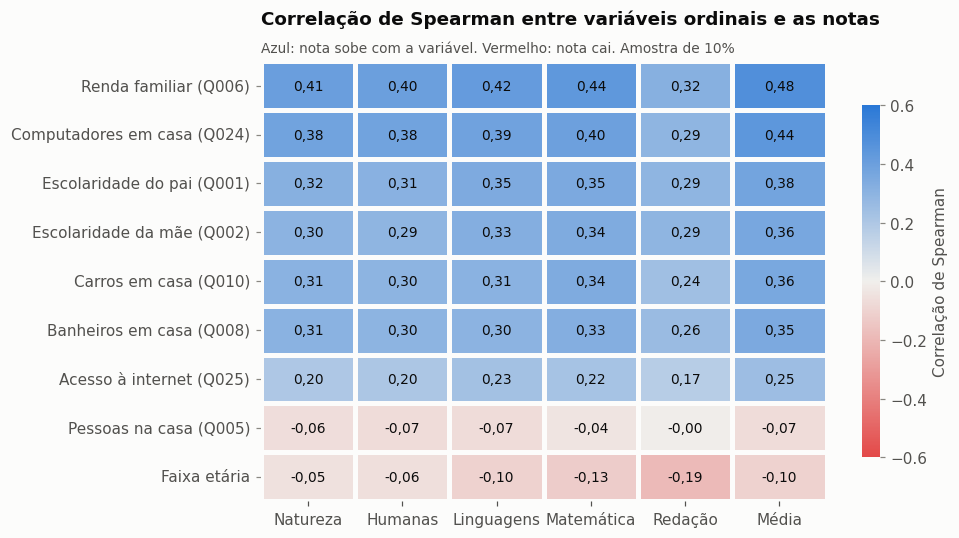

In [10]:
ordinal = pd.DataFrame({
    "Renda familiar (Q006)": amostra["q006"].map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")}),
    "Escolaridade do pai (Q001)": amostra["q001"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Escolaridade da mãe (Q002)": amostra["q002"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Computadores em casa (Q024)": amostra["q024"].map({c: i for i, c in enumerate("ABCDE")}),
    "Acesso à internet (Q025)": amostra["q025"].map({"A": 0, "B": 1}),
    "Banheiros em casa (Q008)": amostra["q008"].map({c: i for i, c in enumerate("ABCDE")}),
    "Carros em casa (Q010)": amostra["q010"].map({c: i for i, c in enumerate("ABCDE")}),
    "Pessoas na casa (Q005)": amostra["q005"],
    "Faixa etária": amostra["tp_faixa_etaria"],
})
notas = amostra[list(PROVAS) + ["nu_nota_redacao", "media"]].rename(columns={
    "nu_nota_cn": "Natureza", "nu_nota_ch": "Humanas", "nu_nota_lc": "Linguagens",
    "nu_nota_mt": "Matemática", "nu_nota_redacao": "Redação", "media": "Média",
})
correlacao = pd.DataFrame({
    coluna_nota: ordinal.corrwith(notas[coluna_nota], method="spearman") for coluna_nota in notas
}).sort_values("Média", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(correlacao, annot=correlacao.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman", "shrink": 0.8},
            annot_kws={"fontsize": 9, "color": TINTA}, ax=ax)
ax.grid(False)
ax.set_title("Correlação de Spearman entre variáveis ordinais e as notas")
subtitulo(ax, "Azul: nota sobe com a variável. Vermelho: nota cai. Amostra de 10%")
ax.tick_params(axis="x", labelrotation=0, colors=TINTA_SECUNDARIA)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "05_correlacao_spearman")

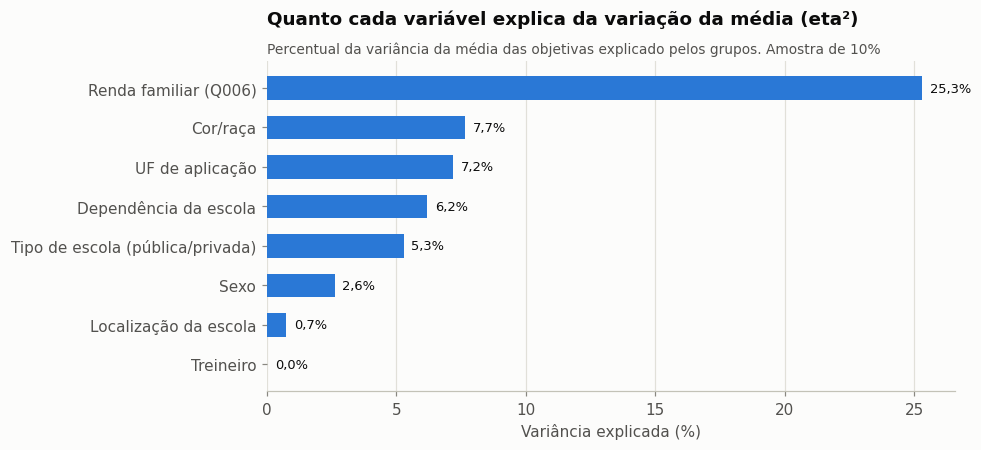

In [11]:
def eta_quadrado(grupo: pd.Series, valor: pd.Series) -> float:
    """Fração da variância de `valor` explicada pelas médias de `grupo`."""
    dados = pd.DataFrame({"g": grupo, "v": valor}).dropna()
    media_total = dados["v"].mean()
    entre = dados.groupby("g")["v"].agg(["count", "mean"])
    soma_entre = (entre["count"] * (entre["mean"] - media_total) ** 2).sum()
    soma_total = ((dados["v"] - media_total) ** 2).sum()
    return soma_entre / soma_total


categoricas = {
    "Tipo de escola (pública/privada)": amostra["ds_escola"],
    "Dependência da escola": amostra["ds_dependencia_adm_esc"],
    "UF de aplicação": amostra["sg_uf_prova"],
    "Cor/raça": amostra["ds_cor_raca"],
    "Treineiro": amostra["ds_treineiro"],
    "Sexo": amostra["ds_sexo"],
    "Localização da escola": amostra["ds_localizacao_esc"],
    "Renda familiar (Q006)": amostra["q006"],
}
eta = pd.Series({nome: eta_quadrado(serie, amostra["media"]) for nome, serie in categoricas.items()}) \
    .sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(eta.index, eta.values * 100, color=AZUL, height=0.6)
for i, valor in enumerate(eta.values):
    ax.text(valor * 100 + 0.3, i, f"{num(valor * 100)}%", va="center", fontsize=8.5, color=TINTA)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Quanto cada variável explica da variação da média (eta²)")
subtitulo(ax, "Percentual da variância da média das objetivas explicado pelos grupos. Amostra de 10%")
ax.set_xlabel("Variância explicada (%)")
salvar(fig, "06_eta_quadrado")

## 3. Dados da redação

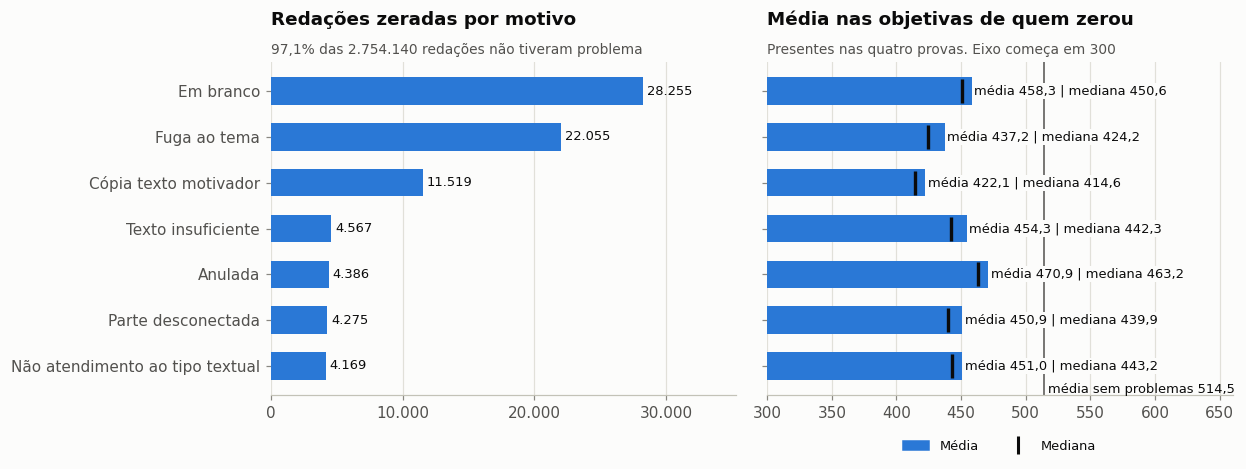

In [12]:
status = consultar("""
    SELECT s.tp_status_redacao, s.ds_status_redacao AS status, COUNT(*) AS participantes
    FROM fato_participacao f JOIN dim_status_redacao s ON s.tp_status_redacao = f.tp_status_redacao
    WHERE f.tp_status_redacao <> 0
    GROUP BY s.tp_status_redacao, s.ds_status_redacao
""")
# Média e mediana nas objetivas por situação da redação, entre os presentes nas quatro provas
objetivas_status = agregar(base, "tp_status_redacao").rename(
    columns={"media": "media_objetivas", "mediana": "mediana_objetivas", "participantes": "presentes"})
objetivas_status["tp_status_redacao"] = objetivas_status["tp_status_redacao"].astype(int)
status = status.merge(objetivas_status, on="tp_status_redacao", how="left")
total_redacoes = status["participantes"].sum()
sem_problemas = status.loc[status["status"] == "Sem problemas", "participantes"].iloc[0]
problemas = status[status["status"] != "Sem problemas"].sort_values("participantes").reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
ax1.barh(problemas["status"], problemas["participantes"], color=AZUL, height=0.6)
for i, valor in enumerate(problemas["participantes"]):
    ax1.text(valor + 300, i, num(valor, 0), va="center", fontsize=8.5, color=TINTA)
ax1.set_title("Redações zeradas por motivo")
subtitulo(ax1, f"{num(100 * sem_problemas / total_redacoes)}% das {num(total_redacoes, 0)} redações não tiveram problema")
ax1.set_xlim(0, problemas["participantes"].max() * 1.25)
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_xticks([0, 10_000, 20_000, 30_000])
ax1.xaxis.set_major_formatter(lambda v, _: num(v, 0))
media_sem_problema = status.loc[status["status"] == "Sem problemas", "media_objetivas"].iloc[0]
barras_com_mediana(ax2, problemas["status"], problemas["media_objetivas"], problemas["mediana_objetivas"])
ax2.axvline(media_sem_problema, color=TINTA_SECUNDARIA, linewidth=1)
ax2.text(media_sem_problema + 3, -0.6, f"média sem problemas {num(media_sem_problema)}", fontsize=8.5,
         color=TINTA)
# Legenda abaixo do eixo, para não cobrir os rótulos das barras
ax2.legend(handles=LEGENDA_BARRAS, loc="upper center", ncols=2, fontsize=8.5, bbox_to_anchor=(0.5, -0.1))
ax2.set_xlim(300, 660)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_title("Média nas objetivas de quem zerou")
subtitulo(ax2, "Presentes nas quatro provas. Eixo começa em 300")
salvar(fig, "07_redacao_status")

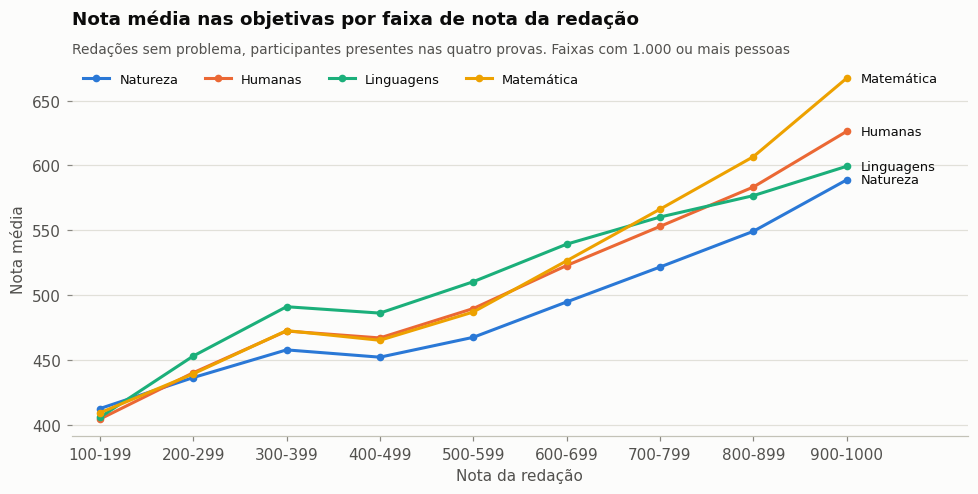

In [13]:
faixas = consultar("""
    SELECT LEAST(FLOOR(nu_nota_redacao / 100) * 100, 900) AS faixa, COUNT(*) AS participantes,
           AVG(nu_nota_cn) AS cn, AVG(nu_nota_ch) AS ch, AVG(nu_nota_lc) AS lc, AVG(nu_nota_mt) AS mt
    FROM fato_participacao
    WHERE nu_media_objetivas IS NOT NULL AND tp_status_redacao = 1
    GROUP BY faixa ORDER BY faixa
""")
faixas = faixas[faixas["participantes"] >= 1000]
fig, ax = plt.subplots(figsize=(9, 4.6))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(faixas["faixa"], faixas[coluna], color=cor, marker="o", markersize=4, label=nome)
    ax.text(faixas["faixa"].iloc[-1] + 15, faixas[coluna].iloc[-1], nome, va="center", fontsize=8.5, color=TINTA)
ax.set_xticks(faixas["faixa"], [f"{int(f)}-{int(f) + 99 if f < 900 else 1000}" for f in faixas["faixa"]])
ax.set_xlim(faixas["faixa"].min() - 30, faixas["faixa"].max() + 130)
ax.legend(loc="upper left", ncols=4, fontsize=8.5)
ax.set_title("Nota média nas objetivas por faixa de nota da redação")
subtitulo(ax, "Redações sem problema, participantes presentes nas quatro provas. Faixas com 1.000 ou mais pessoas")
ax.set_xlabel("Nota da redação")
ax.set_ylabel("Nota média")
salvar(fig, "08_objetivas_por_faixa_redacao")

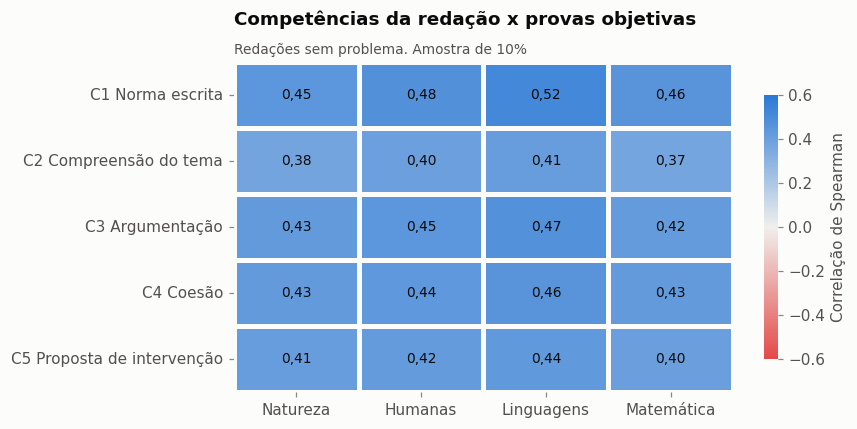

In [14]:
competencias = amostra[amostra["tp_status_redacao"] == 1][
    [f"nu_nota_comp{n}" for n in range(1, 6)] + list(PROVAS)
].corr(method="spearman").iloc[:5, 5:]
competencias.index = ["C1 Norma escrita", "C2 Compreensão do tema", "C3 Argumentação",
                      "C4 Coesão", "C5 Proposta de intervenção"]
competencias.columns = ["Natureza", "Humanas", "Linguagens", "Matemática"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(competencias, annot=competencias.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman", "shrink": 0.8},
            annot_kws={"fontsize": 9, "color": TINTA}, ax=ax)
ax.grid(False)
ax.set_title("Competências da redação x provas objetivas")
subtitulo(ax, "Redações sem problema. Amostra de 10%")
ax.tick_params(axis="x", labelrotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "09_competencias_x_provas")

## 4. Questionário socioeconômico

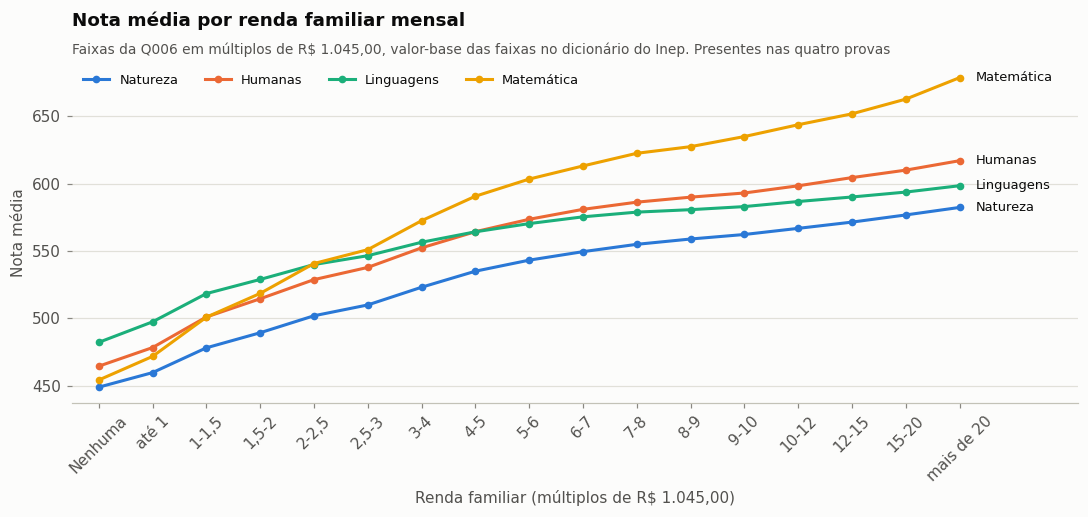

In [15]:
renda = consultar("""
    SELECT q.q006 AS faixa, COUNT(*) AS participantes,
           AVG(f.nu_nota_cn) AS cn, AVG(f.nu_nota_ch) AS ch, AVG(f.nu_nota_lc) AS lc,
           AVG(f.nu_nota_mt) AS mt, AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL AND q.q006 IS NOT NULL
    GROUP BY q.q006 ORDER BY q.q006
""")
rotulos_renda = ["Nenhuma", "até 1", "1-1,5", "1,5-2", "2-2,5", "2,5-3", "3-4", "4-5", "5-6",
                 "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15-20", "mais de 20"]
fig, ax = plt.subplots(figsize=(10, 4.8))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(rotulos_renda, renda[coluna], color=cor, marker="o", markersize=4, label=nome)
    ax.text(16.3, renda[coluna].iloc[-1], nome, va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(-0.5, 18.2)
ax.legend(loc="upper left", ncols=4, fontsize=8.5)
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("Nota média por renda familiar mensal")
subtitulo(ax, "Faixas da Q006 em múltiplos de R$ 1.045,00, valor-base das faixas no dicionário do Inep. Presentes nas quatro provas")
ax.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
ax.set_ylabel("Nota média")
salvar(fig, "10_notas_por_renda")

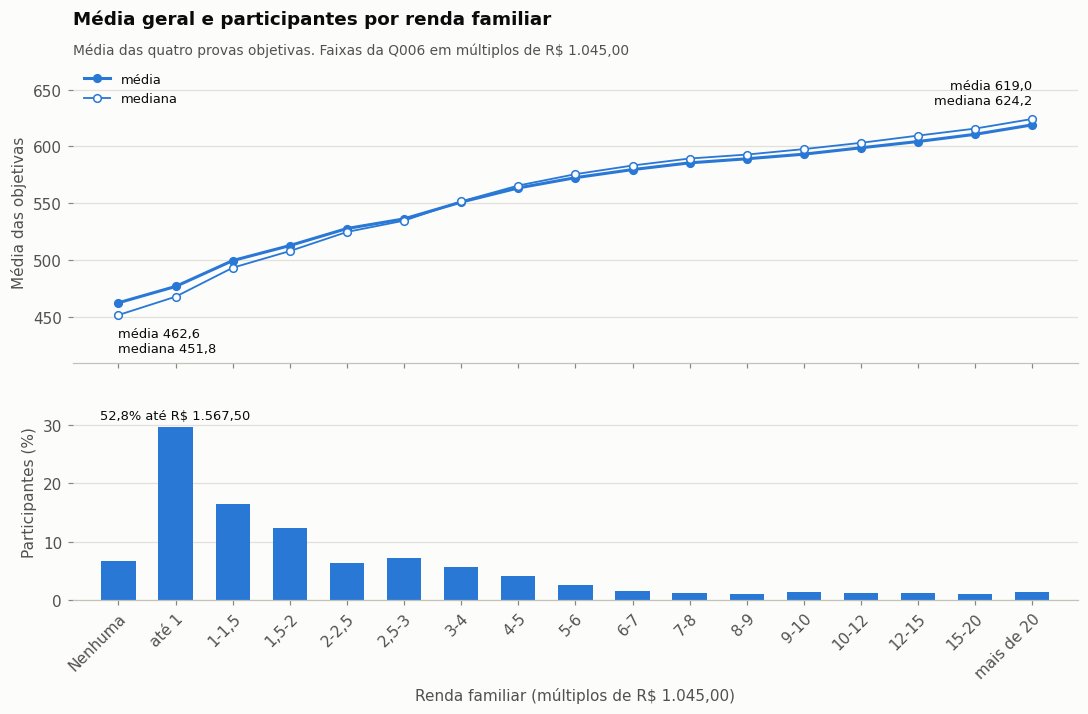

In [16]:
renda_geral = agregar(base, "q006").sort_values("q006").reset_index(drop=True)
renda_geral["pct"] = 100 * renda_geral["participantes"] / renda_geral["participantes"].sum()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
faixas_renda = range(len(rotulos_renda))
linha_com_mediana(ax1, faixas_renda, renda_geral["media"], renda_geral["mediana"], AZUL,
                  rotulo_inicio="below", rotulo_fim="above")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.set_xlim(-0.8, len(rotulos_renda) - 0.2)
ax1.set_ylim(410, 675)
ax1.set_title("Média geral e participantes por renda familiar")
subtitulo(ax1, "Média das quatro provas objetivas. Faixas da Q006 em múltiplos de R$ 1.045,00")
ax1.set_ylabel("Média das objetivas")
ax2.bar(faixas_renda, renda_geral["pct"], color=AZUL, width=0.6)
ax2.set_xticks(faixas_renda, rotulos_renda)
acumulado = renda_geral["pct"].iloc[:3].sum()
ax2.text(1, renda_geral["pct"].max() * 1.05, f"{num(acumulado)}% até R$ 1.567,50", ha="center",
         fontsize=8.5, color=TINTA)
ax2.set_ylim(0, renda_geral["pct"].max() * 1.25)
ax2.set_ylabel("Participantes (%)")
ax2.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
salvar(fig, "15_media_por_renda")

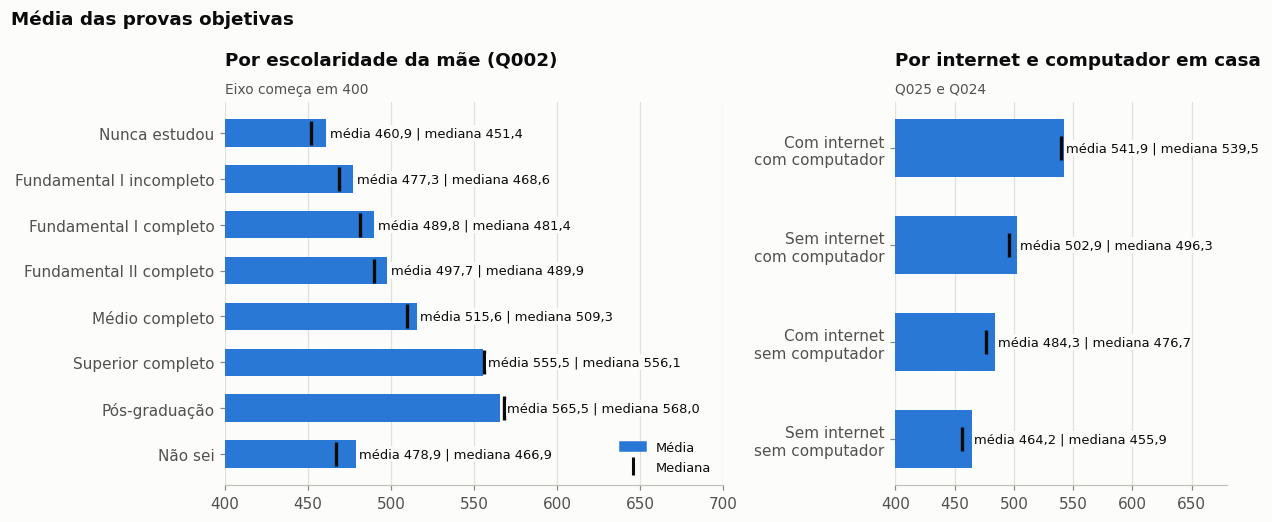

In [17]:
mae = agregar(base, "q002").rename(columns={"q002": "resposta"}).sort_values("resposta") \
    .reset_index(drop=True)
rotulos_mae = {"A": "Nunca estudou", "B": "Fundamental I incompleto", "C": "Fundamental I completo",
               "D": "Fundamental II completo", "E": "Médio completo", "F": "Superior completo",
               "G": "Pós-graduação", "H": "Não sei"}
com_casa = base.dropna(subset=["q024", "q025"]).assign(
    grupo=lambda d: np.where(d["q025"].astype(str) == "B", "Com internet\n", "Sem internet\n")
    + np.where(d["q024"].astype(str) > "A", "com computador", "sem computador"))
casa = agregar(com_casa, "grupo").sort_values("media").reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
barras_com_mediana(ax1, mae["resposta"].astype(str).map(rotulos_mae), mae["media"], mae["mediana"])
ax1.set_xlim(400, 700)
ax1.invert_yaxis()
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.legend(handles=LEGENDA_BARRAS, loc="lower right", fontsize=8.5)
ax1.set_title("Por escolaridade da mãe (Q002)")
subtitulo(ax1, "Eixo começa em 400")
barras_com_mediana(ax2, casa["grupo"], casa["media"], casa["mediana"])
ax2.set_xlim(400, 680)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_title("Por internet e computador em casa")
subtitulo(ax2, "Q025 e Q024")
fig.suptitle("Média das provas objetivas", x=0.01, ha="left", fontsize=12, fontweight="bold")
salvar(fig, "11_media_mae_internet")

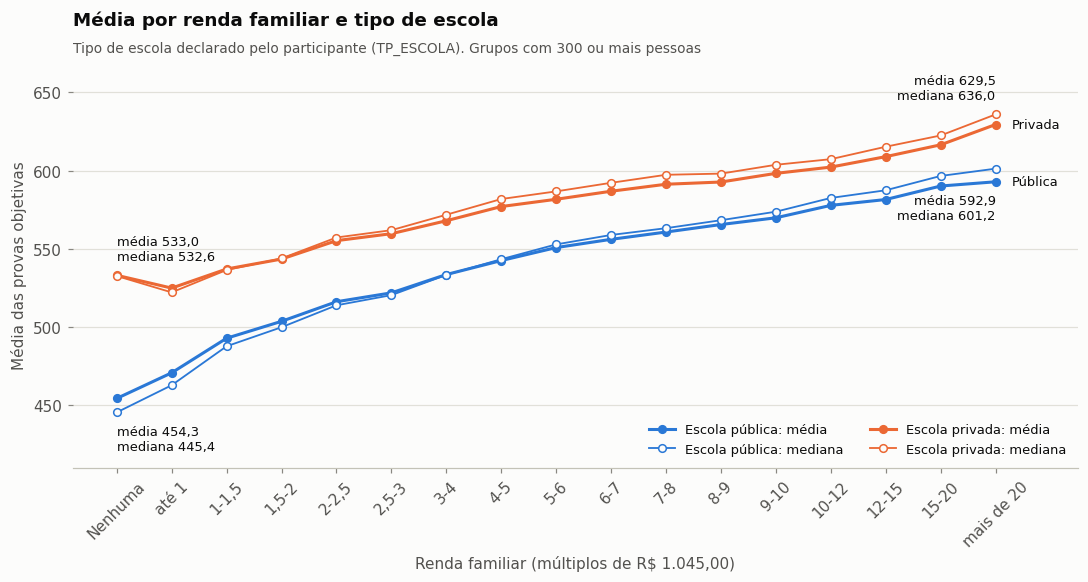

In [18]:
renda_escola = agregar(base[base["ds_escola"].isin(["Pública", "Privada"])], ["q006", "ds_escola"])
renda_escola = renda_escola[renda_escola["participantes"] >= 300]
fig, ax = plt.subplots(figsize=(10, 5.4))
# A escola pública fica embaixo, então seus rótulos vão abaixo dos pontos
for cor, escola, lado in zip(SERIES, ["Pública", "Privada"], ["below", "above"]):
    dados = renda_escola[renda_escola["ds_escola"] == escola].sort_values("q006")
    posicoes = dados["q006"].astype(str).map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")})
    linha_com_mediana(ax, posicoes, dados["media"], dados["mediana"], cor, f"Escola {escola.lower()}",
                      rotulo_inicio=lado, rotulo_fim=lado)
    ax.text(posicoes.iloc[-1] + 0.3, dados["media"].iloc[-1], escola, va="center", fontsize=8.5, color=TINTA)
ax.set_xticks(range(17), rotulos_renda, rotation=45)
ax.set_xlim(-0.8, 17.5)
ax.set_ylim(410, 670)
ax.legend(loc="lower right", fontsize=8.5, ncols=2)
ax.set_title("Média por renda familiar e tipo de escola")
subtitulo(ax, "Tipo de escola declarado pelo participante (TP_ESCOLA). Grupos com 300 ou mais pessoas")
ax.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
ax.set_ylabel("Média das provas objetivas")
salvar(fig, "12_renda_x_tipo_escola")